In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#Set seed so your demo produces the exact same numbers every time
np.random.seed (42)
n_samples = 100


In [3]:
#Create 85 Normal Transactions (Class = 0)
from matplotlib.pylab import size


normal_data={
    'Amount_INR': np.random.randint(150, 15000, size=85),
    'Hour_of_Day': np.random.randint(8, 23, size=85),
    #Daytime/Evening (8 AM - 10 PM)
    'V1_Device_Risk': np.random.normal(-0.5, 0.8, size=85).round(2),
    'V2_Velocity_Score': np.random.normal(-6.4, 0.7, size=85).round(2),
    'Is_International': np.random.choice([0, 1], size=85, p=[0.95, 0.05]),
    'Class': np.zeros (85, dtype=int)
    # 0 normal 1 fraud
}

## Create 15 Fraudulent Transactions (Class = 1)
fraud_data = {
    'Amount_INR': np.random.randint(25000, 95000, size=15),
    'Hour_of_Day': np.random.choice([1, 2, 3, 4, 23], size=15),
    # Late night/early morning
    'V1_Device_Risk': np.random.normal(2.2, 0.9, size=15).round(2),
    'V2_Velocity_Score': np.random.normal(1.9, 0.8, size=15).round(2),
    'Is_International': np.random.choice([0, 1], size=15, p = [0.40, 0.60] ) ,
    'Class': np.ones(15, dtype=int)
}

In [4]:
normal_df = pd.DataFrame(normal_data)
fraud_df = pd.DataFrame(fraud_data)
df = pd.concat([normal_df, fraud_df], ignore_index=True)
df.sample(frac=1, random_state=41).reset_index(drop=True, inplace=True)
df.head()

,Amount_INR,Hour_of_Day,V1_Device_Risk,V2_Velocity_Score,Is_International,Class
0,7420,13,0.28,-6.54,0,0
1,1010,13,0.14,-7.41,0,0
2,5540,17,0.70,-5.57,0,0
3,13568,11,-0.23,-5.49,0,0
4,5341,13,2.20,-7.01,0,0


In [5]:
df.shape

(100, 6)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Amount_INR         100 non-null    int32  
 1   Hour_of_Day        100 non-null    int64  
 2   V1_Device_Risk     100 non-null    float64
 3   V2_Velocity_Score  100 non-null    float64
 4   Is_International   100 non-null    int64  
 5   Class              100 non-null    int64  
dtypes: float64(2), int32(1), int64(3)
memory usage: 4.4 KB


In [7]:
df.loc[4, "Amount_INR"] = np.nan

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Amount_INR         99 non-null     float64
 1   Hour_of_Day        100 non-null    int64  
 2   V1_Device_Risk     100 non-null    float64
 3   V2_Velocity_Score  100 non-null    float64
 4   Is_International   100 non-null    int64  
 5   Class              100 non-null    int64  
dtypes: float64(3), int64(3)
memory usage: 4.8 KB


In [9]:
df["Amount_INR"] = df["Amount_INR"].fillna(df["Amount_INR"].median())

In [10]:
df.head(8)

,Amount_INR,Hour_of_Day,V1_Device_Risk,V2_Velocity_Score,Is_International,Class
0,7420.0,13,0.28,-6.54,0,0
1,1010.0,13,0.14,-7.41,0,0
2,5540.0,17,0.70,-5.57,0,0
3,13568.0,11,-0.23,-5.49,0,0
4,8583.0,13,2.20,-7.01,0,0
5,12114.0,20,-1.24,-5.97,0,0
6,11434.0,22,-0.82,-5.55,1,0
7,5884.0,9,-0.55,-6.24,0,0


In [11]:
df["Class"].value_counts()

Class
0    85
1    15
Name: count, dtype: int64

In [12]:
df[df["Class"] == 1].head(2)

,Amount_INR,Hour_of_Day,V1_Device_Risk,V2_Velocity_Score,Is_International,Class
85,58496.0,4,1.96,2.54,1,1
86,85692.0,1,1.65,2.39,0,1


<Axes: >

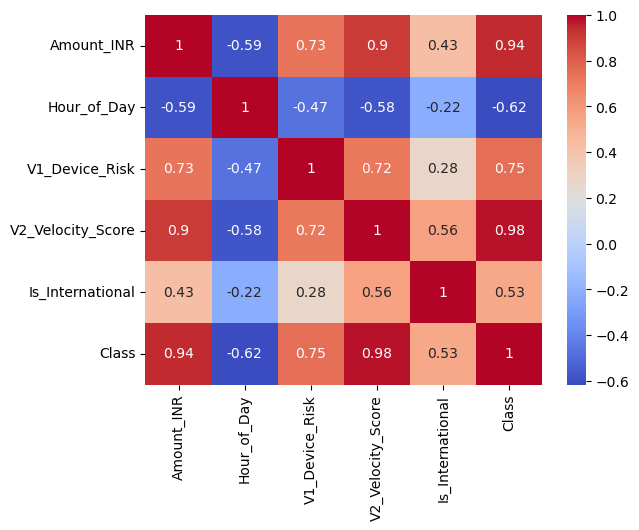

In [13]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

In [14]:
from sklearn.model_selection import train_test_split

# X = Features (The clues), y = Label (The answer)
X = df.drop(columns=['Class'])
y = df['Class']

# Split: 80% Training Data, 20% Testing Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

X_train.shape, X_test.shape, y_train.shape, y_test.shape


((80, 5), (20, 5), (80,), (20,))

In [15]:
from sklearn.linear_model import LogisticRegression

# 1. Initialize and Train the Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print("Model Training Complete!")


Model Training Complete!


In [16]:
model

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [17]:
model.get_params()

{'C': 1.0,
 'class_weight': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': None,
 'max_iter': 1000,
 'multi_class': 'deprecated',
 'n_jobs': None,
 'penalty': 'l2',
 'random_state': None,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

In [18]:
predictions = model.predict(X_test)

In [19]:
model.score(X_test, y_test)

1.0

In [20]:
# 3. Create a clean table of the first 10 test cases WITHOUT actual answers
df = X_test.iloc[:10].copy().reset_index(drop=True)
df['Model_Prediction'] = predictions[:10]

print("\n--- FIRST 10 UNSEEN TEST TRANSACTIONS (ACTUAL LABEL HIDDEN) ---")
df


--- FIRST 10 UNSEEN TEST TRANSACTIONS (ACTUAL LABEL HIDDEN) ---


,Amount_INR,Hour_of_Day,V1_Device_Risk,V2_Velocity_Score,Is_International,Model_Prediction
0,10733.0,19,-0.29,-5.74,0,0
1,11786.0,21,-1.13,-7.07,1,0
2,10297.0,18,-0.06,-7.03,0,0
3,57479.0,1,3.79,1.66,0,1
4,1010.0,13,0.14,-7.41,0,0
5,13953.0,16,-0.25,-7.01,0,0
6,3535.0,15,-0.73,-4.49,0,0
7,86476.0,4,1.92,1.90,1,1
8,10898.0,15,-1.23,-6.43,0,0
9,10383.0,19,-0.44,-5.39,0,0


In [21]:
# Reveal the ground truth alongside the model's prediction
reveal_df = df[['Amount_INR', 'Hour_of_Day', 'Is_International', 'Model_Prediction']].copy()
reveal_df['Actual_Label'] = y_test.iloc[:10].values

# Helper column to label each outcome clearly
def classify_result(row):
    if row['Actual_Label'] == 1 and row['Model_Prediction'] == 1:
        return "✅ True Positive (Caught Fraud!)"
    elif row['Actual_Label'] == 0 and row['Model_Prediction'] == 0:
        return "✅ True Negative (Cleared Genuine)"
    elif row['Actual_Label'] == 0 and row['Model_Prediction'] == 1:
        return "⚠️ False Positive (False Alarm - Blocked Genuine Citizen)"
    else:
        return "🚨 False Negative (Missed Fraud!)"

reveal_df['Outcome_Type'] = reveal_df.apply(classify_result, axis=1)
reveal_df

,Amount_INR,Hour_of_Day,Is_International,Model_Prediction,Actual_Label,Outcome_Type
0,10733.0,19,0,0,0,✅ True Negative (Cleared Genuine)
1,11786.0,21,1,0,0,✅ True Negative (Cleared Genuine)
2,10297.0,18,0,0,0,✅ True Negative (Cleared Genuine)
3,57479.0,1,0,1,1,✅ True Positive (Caught Fraud!)
4,1010.0,13,0,0,0,✅ True Negative (Cleared Genuine)
5,13953.0,16,0,0,0,✅ True Negative (Cleared Genuine)
6,3535.0,15,0,0,0,✅ True Negative (Cleared Genuine)
7,86476.0,4,1,1,1,✅ True Positive (Caught Fraud!)
8,10898.0,15,0,0,0,✅ True Negative (Cleared Genuine)
9,10383.0,19,0,0,0,✅ True Negative (Cleared Genuine)


In [22]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

accuracy_score(y_test, y_pred)

1.0

<Axes: >

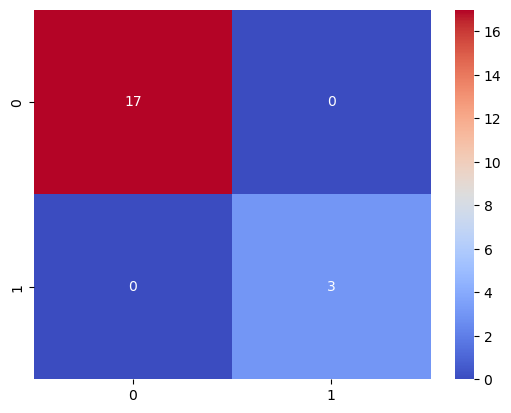

In [23]:
from sklearn.metrics import confusion_matrix, classification_report

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap='coolwarm')

In [24]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        17
           1       1.00      1.00      1.00         3

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



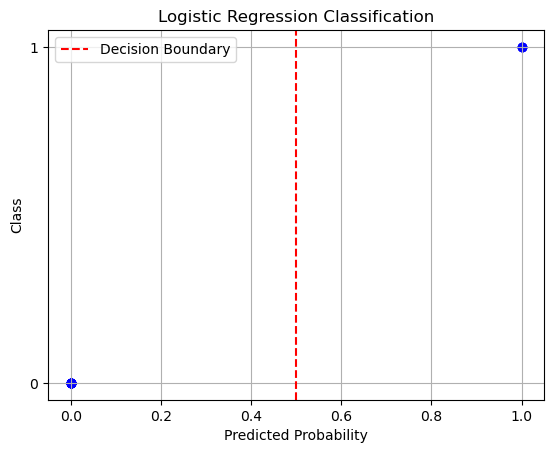

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Predicted probability of Class 1
y_prob = model.predict_proba(X_test)[:, 1]

# Plot actual classes
plt.scatter(y_prob, y_test, color='blue')

# Decision threshold
plt.axvline(x=0.5, color='red',
            linestyle='--', label='Decision Boundary')

plt.xlabel('Predicted Probability')
plt.ylabel('Class')
plt.yticks([0, 1])
plt.title('Logistic Regression Classification')
plt.legend()
plt.grid()
plt.show()

In [26]:
print(X_test.shape)
print(model.coef_)
print(model.intercept_)

(20, 5)
[[ 1.87867175e-03  1.16971008e-04 -6.53548297e-05 -5.36779015e-06
   2.67479118e-05]]
[-45.57519088]
